In [98]:
%pip install pandas numpy matplotlib seaborn jupyter ipykernel


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [100]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: c:\Users\chiya\Downloads\Weintern_projects\project_1\notebooks
Files in this folder: ['outputs', 'P1_task1.ipynb']


In [101]:
file_path = "C:/Users/chiya/Downloads/Weintern_projects/project_1/data/raw/ecommerce_sales_analytics_5000.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (5000, 12)


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [102]:
print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue']


In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


In [104]:
print(df.isnull().sum())

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64


In [105]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [106]:
display(df.describe())

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [107]:
df_clean = df.copy()

print("Original rows:", len(df_clean))

Original rows: 5000


In [108]:
duplicates = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicates)

df_clean = df_clean.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df_clean))

Duplicate rows found: 0
Rows after removing duplicates: 5000


In [109]:
df_clean["order_date"] = pd.to_datetime(
    df_clean["order_date"],
    errors="coerce"
)

print(df_clean["order_date"].dtype)

datetime64[ns]


In [110]:
display(df_clean.isnull().sum())

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [111]:
essential_columns = ["order_id", "order_date", "revenue"]

df_clean = df_clean.dropna(
    subset=essential_columns
).copy()

categorical_columns = [
    "product_category",
    "region",
    "payment_method"
]

for col in categorical_columns:
    df_clean[col] = (
        df_clean[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.title()
    )

numeric_columns = [
    "quantity",
    "unit_price",
    "discount",
    "delivery_days",
    "customer_rating"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

for col in numeric_columns:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

print("Missing values after cleaning:")
display(df_clean.isnull().sum())

Missing values after cleaning:


order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [112]:
print("Quantity <= 0:", (df_clean["quantity"] <= 0).sum())
print("Unit price < 0:", (df_clean["unit_price"] < 0).sum())
print("Discount outside 0-1:",
      (~df_clean["discount"].between(0, 1)).sum())
print("Delivery days < 0:", (df_clean["delivery_days"] < 0).sum())
print("Rating outside 1-5:",
      (~df_clean["customer_rating"].between(1, 5)).sum())
print("Revenue < 0:", (df_clean["revenue"] < 0).sum())

Quantity <= 0: 0
Unit price < 0: 0
Discount outside 0-1: 0
Delivery days < 0: 0
Rating outside 1-5: 0
Revenue < 0: 0


In [113]:
df_clean["product_category"] = (
    df_clean["product_category"].str.strip().str.title()
)

df_clean["region"] = (
    df_clean["region"].str.strip().str.title()
)

df_clean["payment_method"] = (
    df_clean["payment_method"].str.strip().str.title()
)

print("Final cleaned shape:", df_clean.shape)
print("Duplicate rows remaining:", df_clean.duplicated().sum())

display(df_clean.head())

Final cleaned shape: (5000, 12)
Duplicate rows remaining: 0


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,Cod,6,2.5,644.35
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [114]:
CLEAN_DIR = BASE / "data" / "cleaned"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

clean_path = CLEAN_DIR / "ecommerce_sales_cleaned.csv"

df_clean.to_csv(clean_path, index=False)

print("Cleaned dataset saved to:", clean_path)

Cleaned dataset saved to: c:\Users\chiya\Downloads\Weintern_projects\project_1\data\cleaned\ecommerce_sales_cleaned.csv


In [115]:
CHART_DIR = BASE / "outputs" / "charts"
REPORT_DIR = BASE / "reports"

CHART_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

In [116]:
total_revenue = df_clean["revenue"].sum()
total_orders = df_clean["order_id"].nunique()
average_order_value = total_revenue / total_orders
total_units_sold = df_clean["quantity"].sum()

category_units = (
    df_clean.groupby("product_category")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue = (
    df_clean.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

top_selling_category = category_units.index[0]
top_revenue_category = category_revenue.index[0]

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category",
        "Top Revenue-Generating Category"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        int(total_units_sold),
        top_selling_category,
        top_revenue_category
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue,5109775.74
1,Total Orders,5000
2,Average Order Value,1021.96
3,Total Units Sold,20224
4,Top-Selling Category,Electronics
5,Top Revenue-Generating Category,Electronics


In [117]:
kpi_summary.to_csv(
    REPORT_DIR / "kpi_summary.csv",
    index=False
)

print("KPI summary saved!")

KPI summary saved!


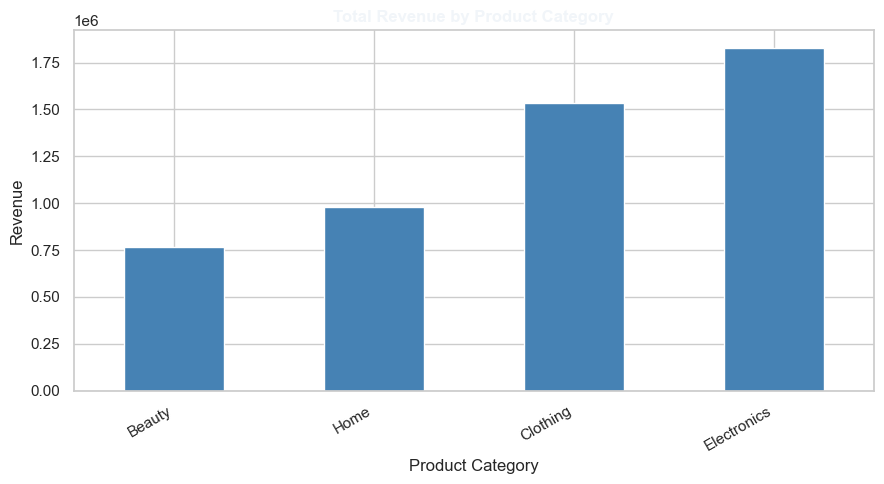

In [118]:
plt.figure(figsize=(9, 5))

category_revenue.sort_values().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "revenue_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

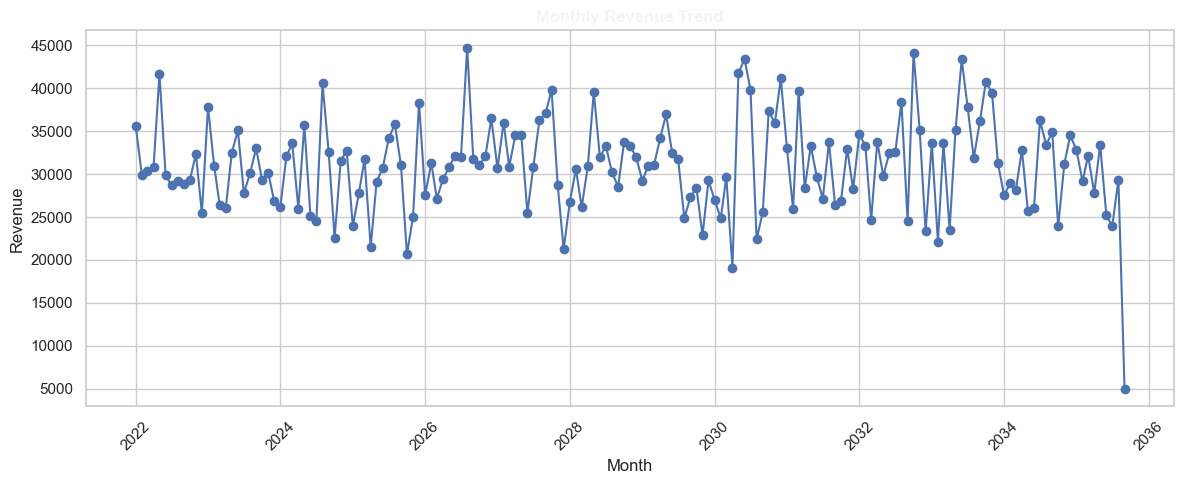

In [119]:
monthly_revenue = (
    df_clean.dropna(subset=["order_date"])
    .set_index("order_date")["revenue"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

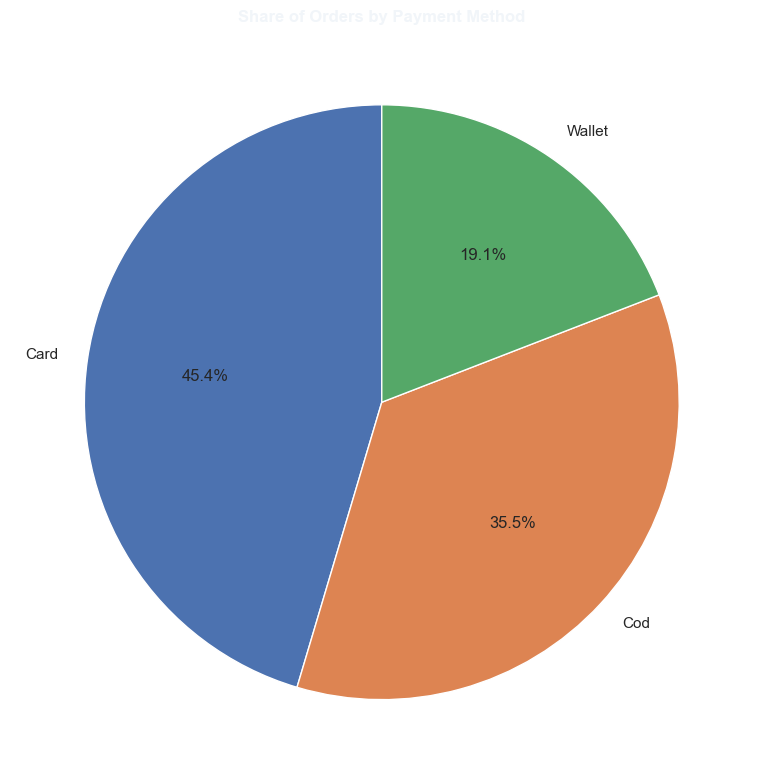

In [120]:
payment_orders = (
    df_clean.groupby("payment_method")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 8))

plt.pie(
    payment_orders,
    labels=payment_orders.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of Orders by Payment Method")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "payment_method_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

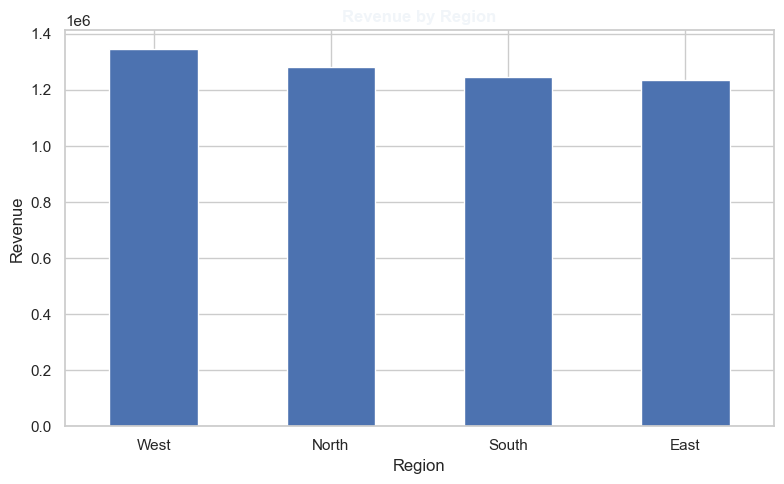

In [121]:
region_revenue = (
    df_clean.groupby("region")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

region_revenue.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "revenue_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [122]:
average_rating = df_clean["customer_rating"].mean()

rating_by_category = (
    df_clean.groupby("product_category")["customer_rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Average customer rating:", round(average_rating, 2))
print("\nAverage rating by category:")
display(rating_by_category.round(2))

Average customer rating: 2.97

Average rating by category:


product_category
Beauty         3.01
Clothing       3.01
Electronics    2.95
Home           2.94
Name: customer_rating, dtype: float64

In [123]:
average_delivery = df_clean["delivery_days"].mean()

delivery_by_region = (
    df_clean.groupby("region")["delivery_days"]
    .mean()
    .sort_values()
)

print("Average delivery days:", round(average_delivery, 2))
print("\nAverage delivery days by region:")
display(delivery_by_region.round(2))

Average delivery days: 6.12

Average delivery days by region:


region
West     6.08
East     6.10
North    6.12
South    6.17
Name: delivery_days, dtype: float64

In [124]:
orders_per_customer = (
    df_clean.groupby("customer_id")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique customers:", df_clean["customer_id"].nunique())
print("Average orders per customer:",
      round(orders_per_customer.mean(), 2))

print("\nTop 10 customers by number of orders:")
display(orders_per_customer.head(10))

Unique customers: 989
Average orders per customer: 5.06

Top 10 customers by number of orders:


customer_id
1663    14
1098    12
1112    12
1957    12
1935    12
1928    12
1669    12
1038    12
1612    11
1658    11
Name: order_id, dtype: int64

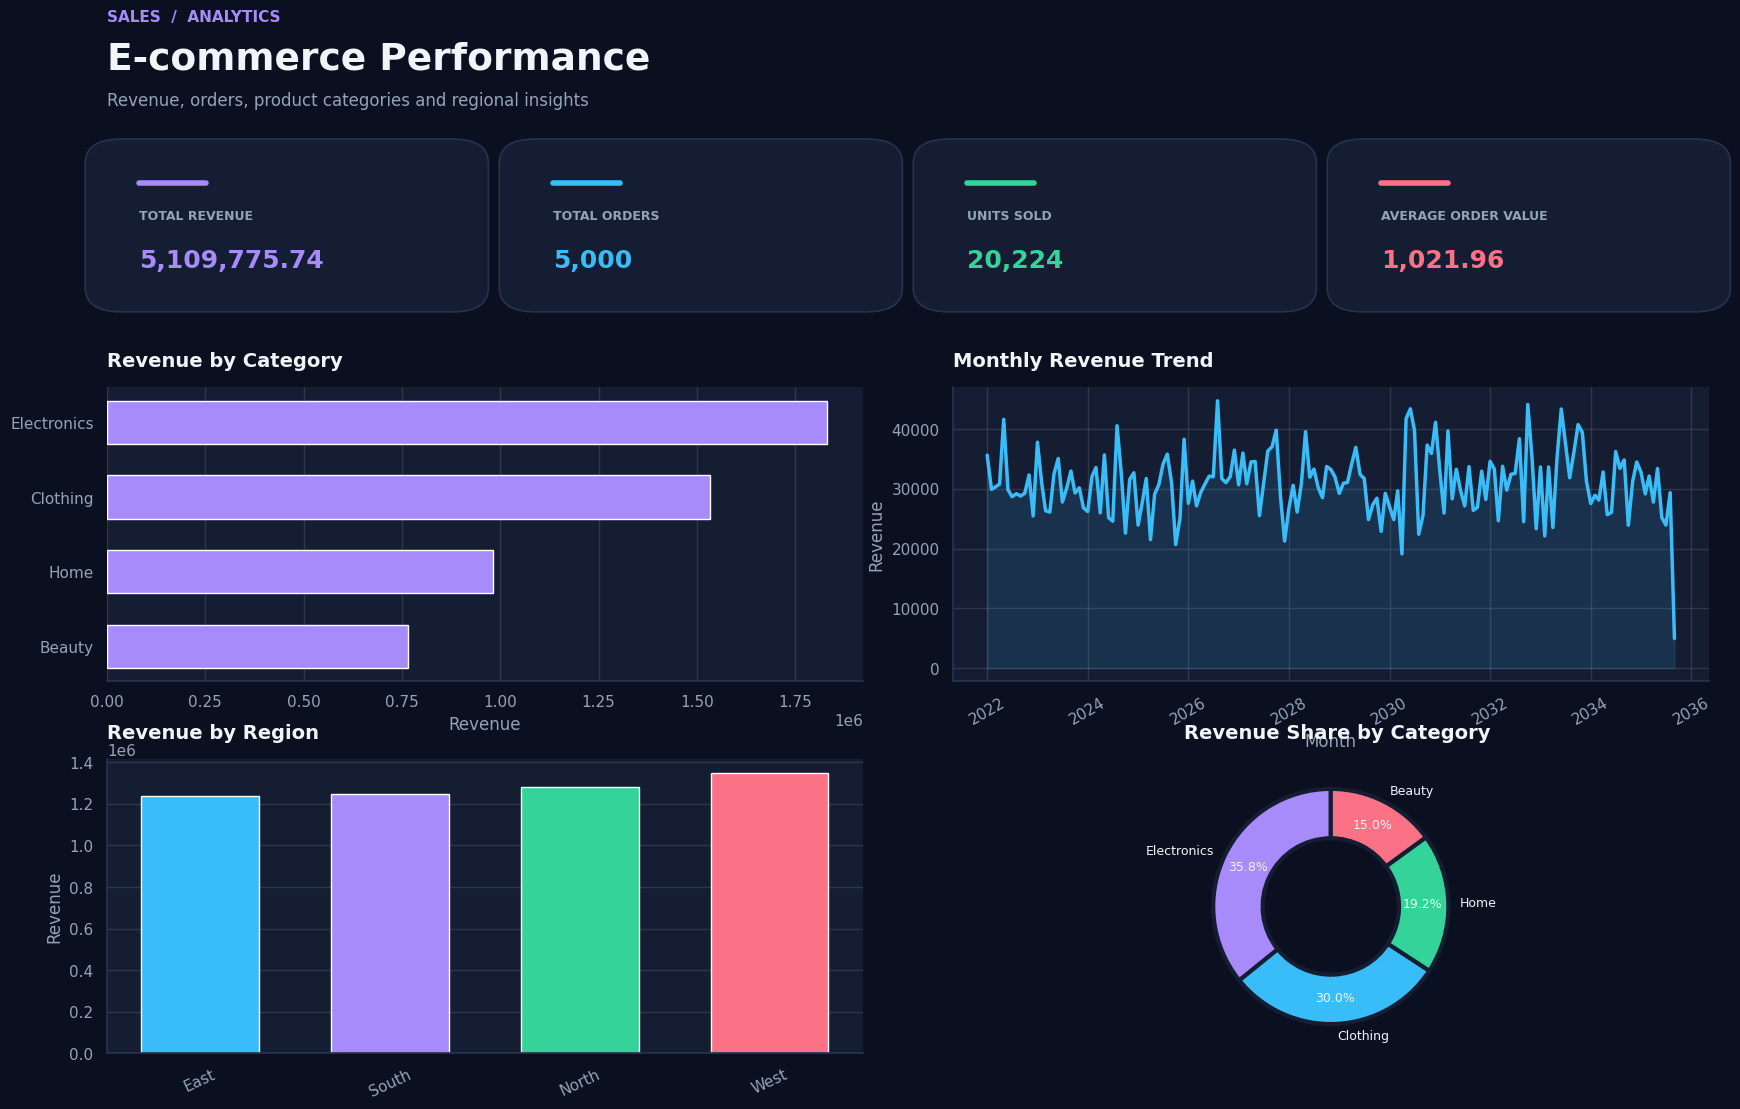

Beautiful dashboard created successfully!
Saved at: outputs\charts\dashboard_mockup.png


In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import FancyBboxPatch

# ==========================
# 1. DASHBOARD THEME
# ==========================

BG = "#0B1020"          # Dark navy background
PANEL = "#151D33"       # Card background
WHITE = "#F1F5F9"
MUTED = "#94A3B8"

PURPLE = "#A78BFA"
BLUE = "#38BDF8"
GREEN = "#34D399"
PINK = "#FB7185"
YELLOW = "#FBBF24"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "axes.edgecolor": "#26334F",
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": WHITE,
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlecolor": WHITE,
})

# ==========================
# 2. CALCULATE METRICS
# ==========================

total_revenue = df_clean["revenue"].sum()
total_orders = df_clean["order_id"].nunique()
total_units_sold = df_clean["quantity"].sum()

average_order_value = (
    total_revenue / total_orders if total_orders else 0
)

category_revenue = (
    df_clean.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=True)
)

monthly_revenue = (
    df_clean.dropna(subset=["order_date"])
    .set_index("order_date")["revenue"]
    .resample("MS")
    .sum()
)

region_revenue = (
    df_clean.groupby("region")["revenue"]
    .sum()
    .sort_values(ascending=True)
)

# ==========================
# 3. CREATE DASHBOARD
# ==========================

fig = plt.figure(figsize=(18, 12), facecolor=BG)

fig.text(
    0.055, 0.955,
    "SALES  /  ANALYTICS",
    fontsize=11,
    color=PURPLE,
    fontweight="bold"
)

fig.text(
    0.055, 0.915,
    "E-commerce Performance",
    fontsize=27,
    fontweight="bold",
    color=WHITE
)

fig.text(
    0.055, 0.885,
    "Revenue, orders, product categories and regional insights",
    fontsize=12,
    color=MUTED
)

# ==========================
# 4. KPI CARDS
# ==========================

kpis = [
    ("TOTAL REVENUE", f"{total_revenue:,.2f}", PURPLE),
    ("TOTAL ORDERS", f"{total_orders:,}", BLUE),
    ("UNITS SOLD", f"{total_units_sold:,}", GREEN),
    ("AVERAGE ORDER VALUE", f"{average_order_value:,.2f}", PINK),
]

card_positions = [
    (0.055, 0.725),
    (0.285, 0.725),
    (0.515, 0.725),
    (0.745, 0.725),
]

for (label, value, color), (x, y) in zip(kpis, card_positions):

    card = FancyBboxPatch(
        (x, y), 0.20, 0.12,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        transform=fig.transFigure,
        facecolor=PANEL,
        edgecolor="#26334F",
        linewidth=1.2
    )
    fig.patches.append(card)

    # Coloured accent
    fig.add_artist(plt.Line2D(
        [x + 0.018, x + 0.055],
        [y + 0.095, y + 0.095],
        transform=fig.transFigure,
        color=color,
        linewidth=4,
        solid_capstyle="round"
    ))

    fig.text(
        x + 0.018, y + 0.065,
        label,
        fontsize=9,
        color=MUTED,
        fontweight="bold"
    )

    fig.text(
        x + 0.018, y + 0.025,
        value,
        fontsize=18,
        color=color,
        fontweight="bold"
    )

# ==========================
# 5. CHART LAYOUT
# ==========================

ax1 = fig.add_axes([0.055, 0.405, 0.42, 0.245])
ax2 = fig.add_axes([0.525, 0.405, 0.42, 0.245])
ax3 = fig.add_axes([0.055, 0.095, 0.42, 0.245])
ax4 = fig.add_axes([0.525, 0.095, 0.42, 0.245])

# ==========================
# 6. REVENUE BY CATEGORY
# ==========================

ax1.barh(
    category_revenue.index.astype(str),
    category_revenue.values,
    color=PURPLE,
    height=0.58
)

ax1.set_title("Revenue by Category", loc="left", pad=15, fontsize=14)
ax1.set_xlabel("Revenue")
ax1.grid(axis="x", alpha=0.15)
ax1.grid(axis="y", visible=False)
ax1.spines[["top", "right", "left"]].set_visible(False)

# ==========================
# 7. MONTHLY REVENUE TREND
# ==========================

ax2.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    color=BLUE,
    linewidth=2.5
)

ax2.fill_between(
    monthly_revenue.index,
    monthly_revenue.values,
    color=BLUE,
    alpha=0.13
)

ax2.set_title("Monthly Revenue Trend", loc="left", pad=15, fontsize=14)
ax2.set_xlabel("Month")
ax2.set_ylabel("Revenue")
ax2.grid(alpha=0.15)
ax2.spines[["top", "right"]].set_visible(False)
ax2.tick_params(axis="x", rotation=30)

# ==========================
# 8. REVENUE BY REGION
# ==========================

region_colors = [BLUE, PURPLE, GREEN, PINK, YELLOW]

ax3.bar(
    region_revenue.index.astype(str),
    region_revenue.values,
    color=region_colors[:len(region_revenue)],
    width=0.62
)

ax3.set_title("Revenue by Region", loc="left", pad=15, fontsize=14)
ax3.set_ylabel("Revenue")
ax3.grid(axis="y", alpha=0.15)
ax3.grid(axis="x", visible=False)
ax3.spines[["top", "right"]].set_visible(False)
ax3.tick_params(axis="x", rotation=25)

# ==========================
# 9. REVENUE SHARE BY CATEGORY
# ==========================

category_share = (
    df_clean.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

ax4.pie(
    category_share.values,
    labels=category_share.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    colors=[
        PURPLE, BLUE, GREEN, PINK, YELLOW,
        "#F97316", "#22D3EE"
    ][:len(category_share)],
    wedgeprops={
        "width": 0.42,
        "edgecolor": PANEL,
        "linewidth": 3
    },
    textprops={"color": WHITE, "fontsize": 9},
    pctdistance=0.78
)

ax4.set_title("Revenue Share by Category", loc="left", pad=15, fontsize=14)

# ==========================
# 10. SAVE DASHBOARD
# ==========================

CHART_DIR = Path("outputs") / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "dashboard_mockup.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=BG
)

plt.show()

print("Beautiful dashboard created successfully!")
print("Saved at:", CHART_DIR / "dashboard_mockup.png")

In [126]:
best_month = monthly_revenue.idxmax()
worst_month = monthly_revenue.idxmin()

best_region = region_revenue.idxmax()
best_payment = payment_orders.idxmax()
highest_rating_category = rating_by_category.idxmax()
fastest_region = delivery_by_region.idxmin()

observations = [
    f"1. Total revenue is {total_revenue:,.2f}.",
    f"2. The dataset contains {total_orders:,} unique orders.",
    f"3. Average order value is {average_order_value:,.2f}.",
    f"4. The highest-selling category by quantity is {top_selling_category}.",
    f"5. The highest-revenue category is {top_revenue_category}.",
    f"6. The highest-revenue month is {best_month.strftime('%B %Y')}, "
    f"with revenue of {monthly_revenue.max():,.2f}.",
    f"7. The highest-revenue region is {best_region}.",
    f"8. The most-used payment method by unique orders is {best_payment}."
]

print("KEY FINDINGS\n")

for observation in observations:
    print(observation)

print("\nCUSTOMER INSIGHTS")
print("Average customer rating:", round(average_rating, 2))
print("Highest average rating category:", highest_rating_category)
print("Fastest average delivery region:", fastest_region)
print("Average delivery time in days:", round(average_delivery, 2))

KEY FINDINGS

1. Total revenue is 5,109,775.74.
2. The dataset contains 5,000 unique orders.
3. Average order value is 1,021.96.
4. The highest-selling category by quantity is Electronics.
5. The highest-revenue category is Electronics.
6. The highest-revenue month is August 2026, with revenue of 44,728.82.
7. The highest-revenue region is West.
8. The most-used payment method by unique orders is Card.

CUSTOMER INSIGHTS
Average customer rating: 2.97
Highest average rating category: Beauty
Fastest average delivery region: West
Average delivery time in days: 6.12


In [127]:
report_text = f"""
E-COMMERCE SALES DATA ANALYSIS
==============================

1. OBJECTIVE
Analyze e-commerce sales data to understand sales performance,
customer behavior, regional results, and monthly revenue trends.

2. DATASET OVERVIEW
Original dataset rows: {len(df)}
Original dataset columns: {len(df.columns)}
Cleaned dataset rows: {len(df_clean)}
Cleaned dataset columns: {len(df_clean.columns)}

3. DATA CLEANING
- Created a separate copy of the original dataset.
- Checked and removed exact duplicate rows.
- Converted order_date into a datetime data type.
- Removed records missing essential order ID, date, or revenue.
- Filled missing categorical values with Unknown.
- Converted numerical columns into numeric data types.
- Filled remaining missing numerical values with their medians.
- Standardized category, region, and payment method text.
- Checked numerical values for invalid ranges.

Note: Review the validation results and document any additional
corrections or removals performed.

4. KPI SUMMARY
Total Revenue: {total_revenue:,.2f}
Total Orders: {total_orders:,}
Average Order Value: {average_order_value:,.2f}
Total Units Sold: {total_units_sold:,}
Top-Selling Category: {top_selling_category}
Top Revenue-Generating Category: {top_revenue_category}

5. SALES TREND
Highest-Revenue Month: {best_month.strftime('%B %Y')}
Revenue in Highest-Revenue Month: {monthly_revenue.max():,.2f}
Lowest-Revenue Month: {worst_month.strftime('%B %Y')}
Revenue in Lowest-Revenue Month: {monthly_revenue.min():,.2f}

Interpret the monthly chart to determine whether revenue shows
growth, decline, seasonality, or fluctuations.

6. CUSTOMER INSIGHTS
Unique Customers: {df_clean['customer_id'].nunique():,}
Average Customer Rating: {average_rating:.2f}
Average Delivery Time: {average_delivery:.2f} days
Highest Average Rating Category: {highest_rating_category}
Fastest Average Delivery Region: {fastest_region}

7. REGIONAL AND PAYMENT ANALYSIS
Highest-Revenue Region: {best_region}
Most-Used Payment Method: {best_payment}

8. KEY FINDINGS
{chr(10).join(observations)}

9. VISUALIZATIONS
- Revenue by product category
- Monthly revenue trend
- Payment method share
- Revenue by region
- Dashboard mockup

10. LIMITATIONS
- The dataset has product categories but no individual product names.
  Therefore, the top revenue-generating individual product cannot
  be identified.
- Findings describe the supplied dataset and do not establish
  the causes of sales or customer behavior.
- Recommendations should be based on the observed results and
  validated with additional business information where possible.

11. RECOMMENDATIONS
- Review the categories generating the most revenue and units sold.
- Investigate months with unusually high or low revenue.
- Compare delivery performance across regions.
- Use customer ratings to identify categories that may need review.
- Monitor payment method preferences when planning checkout options.
"""

report_path = REPORT_DIR / "week1_analysis_report.txt"
report_path.write_text(report_text, encoding="utf-8")

print("Report saved to:", report_path)

Report saved to: c:\Users\chiya\Downloads\Weintern_projects\project_1\reports\week1_analysis_report.txt


In [128]:
print("Cleaned data exists:", clean_path.exists())
print("KPI summary exists:",
      (REPORT_DIR / "kpi_summary.csv").exists())
print("Report exists:", report_path.exists())

print("\nSaved charts:")
for file in sorted(CHART_DIR.glob("*.png")):
    print("-", file.name)

print("\nProject analysis completed!")

Cleaned data exists: True
KPI summary exists: True
Report exists: True

Saved charts:
- dashboard_mockup.png

Project analysis completed!
